In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual profesional
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
np.random.seed(2027) # Semilla para que tus resultados sean 100% reproducibles

# ==============================================================================
# 1. BASE DE DATOS DE AGENTES LIBRES (MLB 2026-2027)
# ==============================================================================
# fWAR_Base: Proyección inicial para 2027 basada en métricas avanzadas (FIP, wRC+, OAA)
# Volatilidad: Desviación estándar anual en WAR (historial médico y varianza estadística)
jugadores = [
    {'Jugador': 'Brandon Lowe',      'Pos': '2B', 'Edad': 32, 'fWAR_Base': 4.6, 'AAV_M': 20.0, 'Anios': 4, 'Volatilidad': 0.85},
    {'Jugador': 'Trevor Rogers',     'Pos': 'SP', 'Edad': 29, 'fWAR_Base': 3.9, 'AAV_M': 20.0, 'Anios': 4, 'Volatilidad': 1.15},
    {'Jugador': 'Teruaki Sato',      'Pos': '3B', 'Edad': 28, 'fWAR_Base': 4.3, 'AAV_M': 16.5, 'Anios': 5, 'Volatilidad': 1.25},
    {'Jugador': 'Luis Arraez',       'Pos': '2B', 'Edad': 30, 'fWAR_Base': 3.8, 'AAV_M': 12.5, 'Anios': 4, 'Volatilidad': 0.60},
    {'Jugador': 'Ryan Jeffers',      'Pos': 'C',  'Edad': 30, 'fWAR_Base': 3.2, 'AAV_M': 18.0, 'Anios': 2, 'Volatilidad': 0.90},
    {'Jugador': 'Tarik Skubal',      'Pos': 'SP', 'Edad': 30, 'fWAR_Base': 5.8, 'AAV_M': 44.0, 'Anios': 8, 'Volatilidad': 1.45},
    {'Jugador': 'Nick Martinez',     'Pos': 'SP', 'Edad': 36, 'fWAR_Base': 2.7, 'AAV_M': 16.0, 'Anios': 2, 'Volatilidad': 0.75},
    {'Jugador': 'David Bednar',      'Pos': 'RP', 'Edad': 32, 'fWAR_Base': 1.6, 'AAV_M': 18.0, 'Anios': 4, 'Volatilidad': 0.70},
    {'Jugador': 'Christian Walker',  'Pos': '1B', 'Edad': 36, 'fWAR_Base': 3.1, 'AAV_M': 21.0, 'Anios': 3, 'Volatilidad': 0.80},
    {'Jugador': 'Alex Bregman',      'Pos': '3B', 'Edad': 33, 'fWAR_Base': 3.7, 'AAV_M': 27.5, 'Anios': 4, 'Volatilidad': 0.75}
]

df = pd.DataFrame(jugadores)

# ==============================================================================
# 2. PARÁMETROS FINANCIEROS Y SABERMÉTRICOS DEL MERCADO
# ==============================================================================
VALOR_WAR_2027 = 8.1       # Millones de dólares por cada 1.0 WAR en el mercado abierto
INFLACION_SALARIAL = 0.04  # El precio del WAR sube ~4% anual en la MLB
TASA_DESCUENTO = 0.05      # Tasa financiera para traer flujos futuros a Valor Presente (VPN)
SIMULACIONES = 10000       # Escenarios por jugador

# ==============================================================================
# 3. MOTOR DE SIMULACIÓN DE MONTE CARLO
# ==============================================================================
resultados = []

for _, row in df.iterrows():
    surplus_simulaciones = []
    war_total_simulaciones = []

    for _ in range(SIMULACIONES):
        vpn_valor_producido = 0
        vpn_costo_contrato = 0
        war_acumulado = 0

        for anio in range(row['Anios']):
            edad_actual = row['Edad'] + anio

            # Curva de envejecimiento: después de los 30, pierde 0.35 WAR por año de edad
            penalizacion_edad = max(0, (edad_actual - 30) * 0.35)
            war_esperado_anio = max(0, row['fWAR_Base'] - penalizacion_edad)

            # Simulación estocástica del rendimiento real en ese año (mínimo -1.0 WAR)
            war_simulado = max(-1.0, np.random.normal(war_esperado_anio, row['Volatilidad']))
            war_acumulado += war_simulado

            # Valor en dólares de ese WAR ajustado por inflación de mercado
            precio_war_anio = VALOR_WAR_2027 * ((1 + INFLACION_SALARIAL) ** anio)
            valor_generado_anio = war_simulado * precio_war_anio

            # Descuento financiero a Valor Presente Neto (VPN)
            factor_vpn = (1 + TASA_DESCUENTO) ** anio
            vpn_valor_producido += valor_generado_anio / factor_vpn
            vpn_costo_contrato += row['AAV_M'] / factor_vpn

        surplus_neto = vpn_valor_producido - vpn_costo_contrato
        surplus_simulaciones.append(surplus_neto)
        war_total_simulaciones.append(war_acumulado)

    surplus_simulaciones = np.array(surplus_simulaciones)

    resultados.append({
        'Jugador': row['Jugador'],
        'Pos': row['Pos'],
        'Edad_2027': row['Edad'],
        'Contrato': f"{row['Anios']}a / ${row['AAV_M']*row['Anios']:.0f}M",
        'AAV_M': row['AAV_M'],
        'WAR_Total_Esp': np.mean(war_total_simulaciones),
        'Surplus_VPN_Medio_M': np.mean(surplus_simulaciones),
        'Prob_Exito_%': np.mean(surplus_simulaciones > 0) * 100, # Probabilidad de generar ganancia neta
        'Peor_Escenario_P10_M': np.percentile(surplus_simulaciones, 10) # Riesgo de caída (VaR 10%)
    })

df_resultados = pd.DataFrame(resultados).sort_values(by='Surplus_VPN_Medio_M', ascending=False)

# Mostrar tabla ejecutiva formateada
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("=== RESULTADOS DE LA SIMULACIÓN DE MONTE CARLO (10,000 ESCENARIOS) ===")
print(df_resultados.round(2).to_string(index=False))

=== RESULTADOS DE LA SIMULACIÓN DE MONTE CARLO (10,000 ESCENARIOS) ===
         Jugador Pos  Edad_2027   Contrato  AAV_M  WAR_Total_Esp  Surplus_VPN_Medio_M  Prob_Exito_%  Peor_Escenario_P10_M
    Teruaki Sato  3B         28  5a / $82M   16.5          20.47                87.79        100.00                 59.45
     Luis Arraez  2B         30  4a / $50M   12.5          13.12                58.34        100.00                 46.16
   Trevor Rogers  SP         29  4a / $80M   20.0          14.58                42.02         98.86                 18.73
    Brandon Lowe  2B         32  4a / $80M   20.0          13.51                33.59         99.21                 16.27
    Ryan Jeffers   C         30  2a / $36M   18.0           6.05                13.62         90.92                  0.52
    Tarik Skubal  SP         30 8a / $352M   44.0          36.56               -11.02         36.66                -52.49
   Nick Martinez  SP         36  2a / $32M   16.0           0.88           

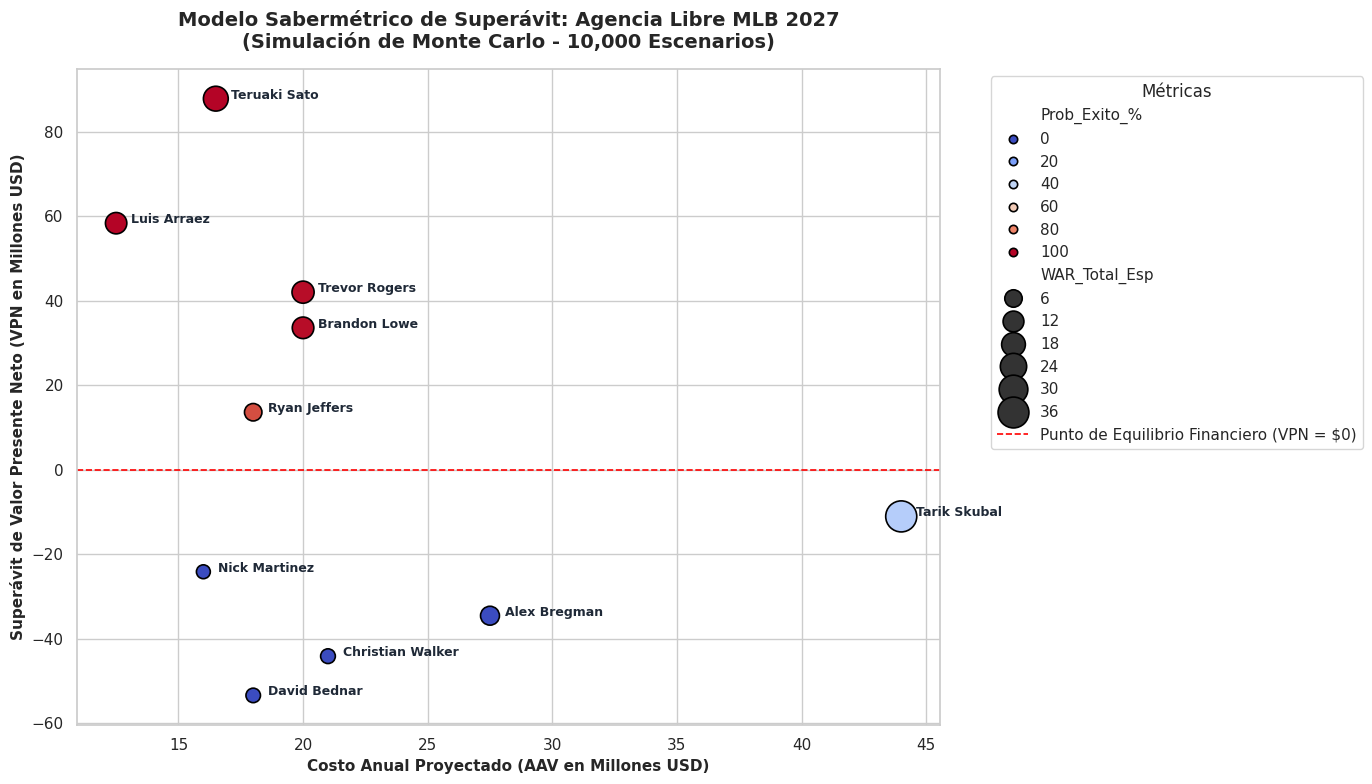

In [2]:
# ==============================================================================
# 4. GENERACIÓN DE GRÁFICOS DE ALTO IMPACTO PARA LINKEDIN
# ==============================================================================
plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Gráfico de Dispersión: Costo Anual (AAV) vs Superávit VPN Esperado
scatter = sns.scatterplot(
    data=df_resultados,
    x='AAV_M',
    y='Surplus_VPN_Medio_M',
    size='WAR_Total_Esp',
    sizes=(100, 500),
    hue='Prob_Exito_%',
    palette='coolwarm',
    edgecolor='black',
    linewidth=1.2
)

plt.axhline(0, color='red', linestyle='--', linewidth=1.2, label='Punto de Equilibrio Financiero (VPN = $0)')
plt.title('Modelo Sabermétrico de Superávit: Agencia Libre MLB 2027\n(Simulación de Monte Carlo - 10,000 Escenarios)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Costo Anual Proyectado (AAV en Millones USD)', fontsize=11, fontweight='bold')
plt.ylabel('Superávit de Valor Presente Neto (VPN en Millones USD)', fontsize=11, fontweight='bold')

# Etiquetar cada jugador en el gráfico
for i, row in df_resultados.iterrows():
    plt.text(
        row['AAV_M'] + 0.6,
        row['Surplus_VPN_Medio_M'],
        row['Jugador'],
        fontsize=9,
        fontweight='bold',
        color='#1f2937'
    )

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Métricas')
plt.tight_layout()
plt.savefig('mlb_montecarlo_surplus.png', dpi=300)
plt.show()